In [1]:
from pyspark.sql import SparkSession
from pyspark.sql.types import (
    StructType, StructField, StringType, DoubleType
)
import time

spark = SparkSession.builder \
    .appName("COVID19_RQ5_MapReduce") \
    .getOrCreate()

sc = spark.sparkContext

In [2]:
data_path = "../../covid.csv"

df = (
    spark.read
    .option("header", "true")
    .option("inferSchema", "true")
    .csv(data_path)
)

print("Number of records:", df.count())
df.printSchema()

Number of records: 10647
root
 |-- dateRep: string (nullable = true)
 |-- year_week: string (nullable = true)
 |-- cases_weekly: integer (nullable = true)
 |-- deaths_weekly: integer (nullable = true)
 |-- countriesAndTerritories: string (nullable = true)
 |-- geoId: string (nullable = true)
 |-- countryterritoryCode: string (nullable = true)
 |-- popData2019: integer (nullable = true)
 |-- continentExp: string (nullable = true)
 |-- rate_14d: double (nullable = true)



In [3]:
def mapper5(row):
    continent = row["continentExp"]
    week = row["year_week"]
    cases = row["cases_weekly"]
    deaths = row["deaths_weekly"]

    if continent is None or week is None or cases is None or deaths is None:
        return None

    return (
        continent,
        {
            week: (float(cases), float(deaths))
        }
    )

In [4]:
def reducer5(a, b):
    merged = dict(a)

    for week, values in b.items():
        if week not in merged:
            merged[week] = values
        else:
            merged[week] = (
                merged[week][0] + values[0],
                merged[week][1] + values[1]
            )

    return merged

In [5]:
start_time = time.time()

mapped = (
    df.select(
        "continentExp",
        "year_week",
        "cases_weekly",
        "deaths_weekly"
    )
    .rdd
    .map(mapper5)
    .filter(lambda x: x is not None)
)

reduced = mapped.reduceByKey(reducer5)

results = reduced.collect()

end_time = time.time()
execution_time = end_time - start_time

print("MapReduce execution time: {:.4f} seconds".format(execution_time))

MapReduce execution time: 1.0158 seconds


In [6]:
final_results = []

for continent, weekly_totals in results:

    peak_cases = max(values[0] for values in weekly_totals.values())
    peak_deaths = max(values[1] for values in weekly_totals.values())

    peak_cases_weeks = sorted(
        week for week, values in weekly_totals.items()
        if values[0] == peak_cases
    )

    peak_deaths_weeks = sorted(
        week for week, values in weekly_totals.items()
        if values[1] == peak_deaths
    )

    final_results.append((
        continent,
        ", ".join(peak_cases_weeks),
        float(peak_cases),
        ", ".join(peak_deaths_weeks),
        float(peak_deaths)
    ))

In [9]:
schema = StructType([
    StructField("continent", StringType(), False),
    StructField("peak_cases_weeks", StringType(), False),
    StructField("peak_cases", DoubleType(), False),
    StructField("peak_deaths_weeks", StringType(), False),
    StructField("peak_deaths", DoubleType(), False)
])

final_df = spark.createDataFrame(
    final_results,
    schema
).orderBy("continent")

final_df.show(truncate=False)

+---------+----------------+----------+-----------------+-----------+
|continent|peak_cases_weeks|peak_cases|peak_deaths_weeks|peak_deaths|
+---------+----------------+----------+-----------------+-----------+
|Africa   |2021-01         |227221.0  |2021-03          |6501.0     |
|America  |2021-01         |2699838.0 |2021-03          |48277.0    |
|Asia     |2020-38         |851577.0  |2020-38          |12466.0    |
|Europe   |2020-45         |2092934.0 |2021-03          |39948.0    |
|Oceania  |2020-31         |3607.0    |2020-36          |148.0      |
|Other    |2020-08         |336.0     |2020-08, 2020-09 |3.0        |
+---------+----------------+----------+-----------------+-----------+



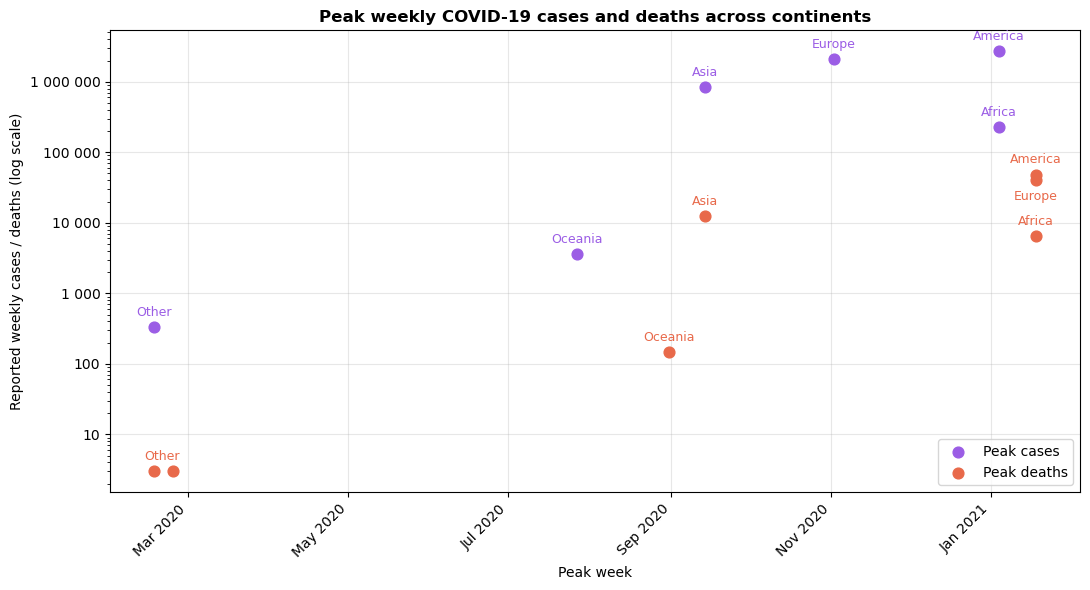

In [19]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from datetime import date
from matplotlib.ticker import FuncFormatter

# Convert the PySpark DataFrame into Pandas
plot_df = final_df.toPandas()

# Convert the results into the same structure as the original plot
rows = []

for _, row in plot_df.iterrows():
    cases_weeks = [
        w.strip()
        for w in str(row["peak_cases_weeks"]).split(",")
    ]

    deaths_weeks = [
        w.strip()
        for w in str(row["peak_deaths_weeks"]).split(",")
    ]

    rows.append((
        row["continent"],
        cases_weeks,
        float(row["peak_cases"]),
        deaths_weeks,
        float(row["peak_deaths"])
    ))


def iso_week_to_date(s):
    """Convert YYYY-WW into the Monday of the ISO week."""
    year, week = map(int, s.split("-"))
    return date.fromisocalendar(year, week, 1)


# Label offsets
offsets_cases = {
    continent: (0, 8)
    for continent, *_ in rows
}

offsets_deaths = {
    continent: (0, 8)
    for continent, *_ in rows
}

offsets_deaths["Europe"] = (0, -14)
CASES_COLOR = "#9B5DE5"
DEATHS_COLOR = "#E8694A"

fig, ax = plt.subplots(figsize=(11, 6))

for continent, weeks_cases, cases, weeks_deaths, deaths in rows:
    # Plot case peak(s)
    dates_cases = [
        iso_week_to_date(w)
        for w in weeks_cases
    ]

    for peak_date in dates_cases:
        ax.scatter(
            peak_date,
            cases,
            s=60,
            color=CASES_COLOR,
            zorder=3,
            label="Peak cases"
        )

    # One continent label for cases
    mid_cases = dates_cases[0] + (
        dates_cases[-1] - dates_cases[0]
    ) / 2

    ax.annotate(
        continent,
        (mid_cases, cases),
        textcoords="offset points",
        xytext=offsets_cases[continent],
        ha="center",
        fontsize=9,
        color=CASES_COLOR
    )

    # Plot death peak(s)
    dates_deaths = [
        iso_week_to_date(w)
        for w in weeks_deaths
    ]

    for peak_date in dates_deaths:
        ax.scatter(
            peak_date,
            deaths,
            s=60,
            color=DEATHS_COLOR,
            zorder=3,
            label="Peak deaths"
        )

    # One continent label for deaths
    mid_deaths = dates_deaths[0] + (
        dates_deaths[-1] - dates_deaths[0]
    ) / 2

    ax.annotate(
        continent,
        (mid_deaths, deaths),
        textcoords="offset points",
        xytext=offsets_deaths[continent],
        ha="center",
        fontsize=9,
        color=DEATHS_COLOR
    )


# Logarithmic Y-axis
ax.set_yscale("log")
ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda v, _: f"{int(v):,}".replace(",", " ")
    )
)

# Real date axis
ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=2)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha="right"
)

# Titles and labels
ax.set_title(
    "Peak weekly COVID-19 cases and deaths across continents",
    fontweight="bold"
)

ax.set_xlabel("Peak week")
ax.set_ylabel(
    "Reported weekly cases / deaths (log scale)"
)

ax.grid(True, alpha=0.3)

# Legend without duplicates
handles, labels = ax.get_legend_handles_labels()
unique = dict(zip(labels, handles))

ax.legend(
    unique.values(),
    unique.keys(),
    loc="lower right"
)

fig.tight_layout()

fig.savefig(
    "covid_peaks.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


In [8]:
final_df = final_df.orderBy("continent").collect()

for row in final_df:
    print(
        "{}\t{}\t{}\t{}\t{}".format(
            row["continent"],
            row["peak_cases_weeks"],
            row["peak_cases"],
            row["peak_deaths_weeks"],
            row["peak_deaths"]
        )
    )

Africa	2021-01	227221.0	2021-03	6501.0
America	2021-01	2699838.0	2021-03	48277.0
Asia	2020-38	851577.0	2020-38	12466.0
Europe	2020-45	2092934.0	2021-03	39948.0
Oceania	2020-31	3607.0	2020-36	148.0
Other	2020-08	336.0	2020-08, 2020-09	3.0
